*Notebook 09 in `notebooks/arcs/`. Parameters (pre-registered): `analysis/arcs/config.yaml`; decisions and run notes: `analysis/arcs/LOG.md`. The static page `site/arcs/index.html` is built from the same saved outputs.*

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd().resolve().parents[1]   # notebooks/arcs -> repo root
sys.path.insert(0, str(REPO))

import warnings

import pandas as pd
import plotly.io as pio
from IPython.display import Markdown, display

from analysis.scripts_text.report import nb_md
from analysis.static_figures import use_static_figures

from analysis.arcs import s09_robustness as step

use_static_figures()   # figures become static PNGs (they show on GitHub); interactive ones are on the static page
warnings.filterwarnings("ignore", category=RuntimeWarning)   # known 0/0 on very short arcs, handled downstream
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

## Step 9 · Stability and robustness (exploratory)

Does the Step 7 result change when we make different reasonable choices along the way?

One run is not *the* answer. We repeat the Step 7 statistic, with the same controls and the same within-cell
null, while changing one choice at a time:
- **Instrument:** VADER, DistilBERT SST-2, the three-class RoBERTa, the ModernBERT-large model added as
  amendment (d), and the contextual models reading whole scenes in context. Each runs only if it's available.
- **Layer:** dialogue only, and action lines only.
- **Arc:** smoothing windows of 5 and 21, and grids of 50 and 200 points.
- **Sample:** all scripts with franchise films included, each single-source franchise cut, the strict and
  loose arc-ready filters, and the primary sample without possible transcripts.
- **Outcome:** log gross instead of log(gross/budget).
- **Genre rule:** "first listed" instead of the frozen priority rule. The two agree on only 49% of films.
- **Seed:** the permutations and the bootstrap rerun with four other seeds.

Each variant uses 500 permutations and 100 bootstrap resamples. All rows are **exploratory**. With this many
rows, one or two will pass p < 0.05 by chance. The question is whether the sign and the size stay stable.

> **Takeaway.** Swing (D1) keeps the sign of its Step 7 ρ in 16 of the 19 variants that change it, and 2 of them reach p < 0.05. Ending lift (D2) keeps the sign of its Step 7 ρ in 14 of the 15 variants that change it, and 6 of them reach p < 0.05. All of these rows are exploratory, so the Step 7 decision stands.

In [2]:
res = step.run()   # recomputes this step and saves its outputs

**Figure.** One row per variant: ρ with its 95% bootstrap CI. Blue: the primary analysis. Orange: a variant with p < 0.05. Dotted lines: ±r_min, the minimum detectable correlation.

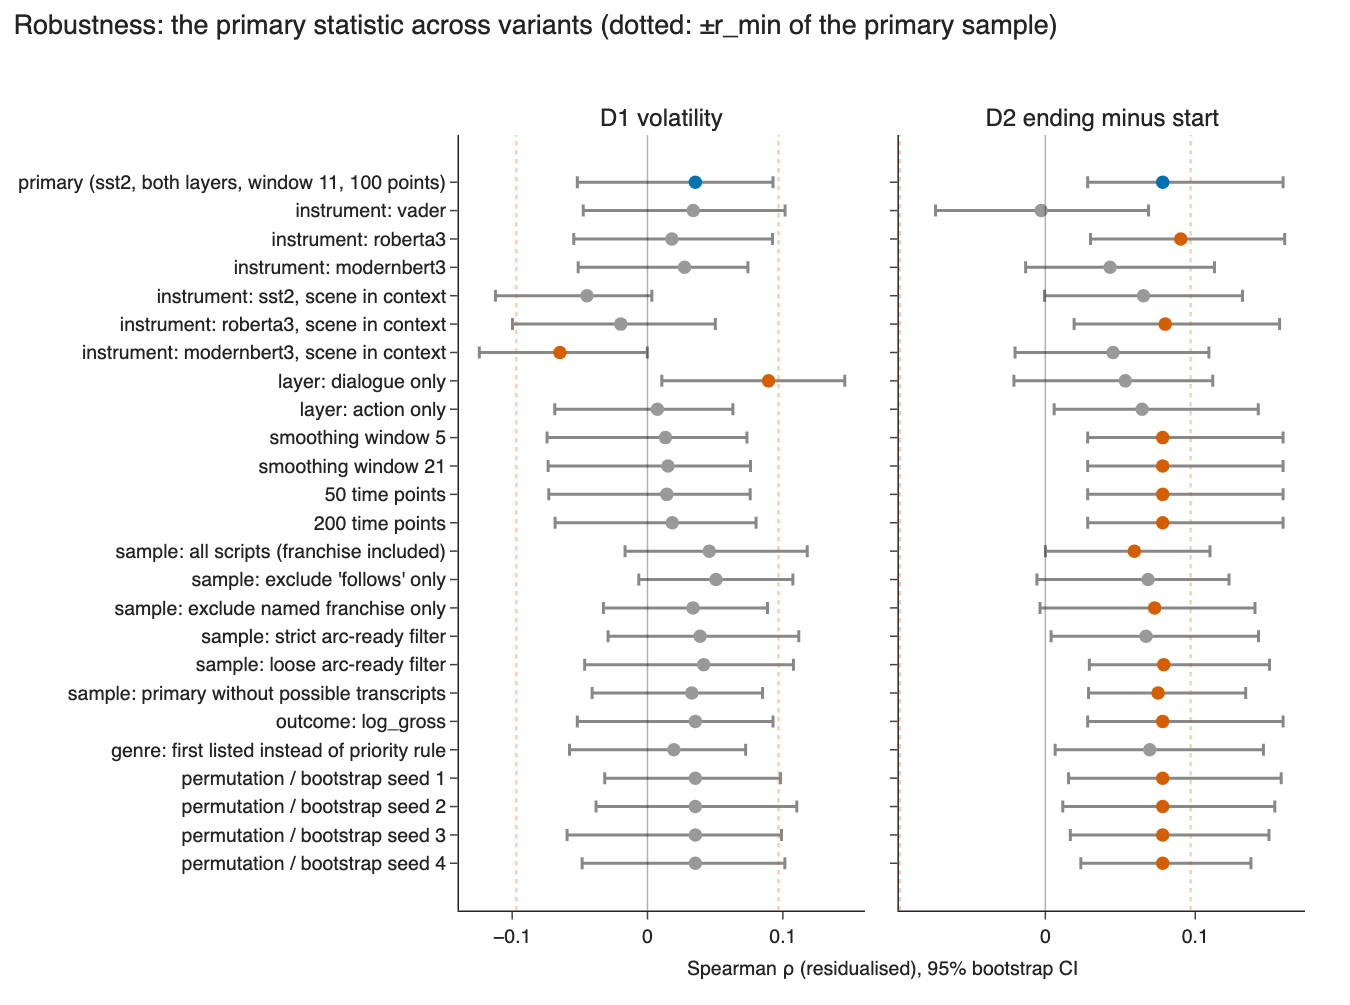

In [3]:
step.figures(res)["forest"].show()

**Table.** Every variant, for both descriptors.

In [4]:
display(step.tables(res)["variants"])

,group,variant,descriptor,N,cells,rho,95% CI,z,p,p < 0.05,r_min_0.05
0,primary,"primary (sst2, both layers, window 11, 100 points)",D1,834,36,0.035,"[-0.052, +0.093]",0.985,0.315,,0.097
1,primary,"primary (sst2, both layers, window 11, 100 points)",D2,834,36,0.078,"[+0.028, +0.159]",2.185,0.018,yes,0.097
2,instrument,instrument: vader,D1,834,36,0.034,"[-0.047, +0.102]",1.102,0.325,,0.097
3,instrument,instrument: vader,D2,834,36,-0.003,"[-0.073, +0.069]",-0.043,0.934,,0.097
4,instrument,instrument: roberta3,D1,834,36,0.018,"[-0.054, +0.092]",0.522,0.581,,0.097
5,instrument,instrument: roberta3,D2,834,36,0.090,"[+0.030, +0.160]",2.609,0.010,yes,0.097
6,instrument,instrument: modernbert3,D1,834,36,0.027,"[-0.051, +0.074]",0.829,0.405,,0.097
7,instrument,instrument: modernbert3,D2,834,36,0.043,"[-0.013, +0.113]",1.147,0.226,,0.097
8,instrument,"instrument: sst2, scene in context",D1,834,36,-0.045,"[-0.112, +0.003]",-1.239,0.188,,0.097
9,instrument,"instrument: sst2, scene in context",D2,834,36,0.065,"[-0.001, +0.131]",1.775,0.072,,0.097


**Plain-language reading** (generated from the saved numbers):

In [5]:
display(Markdown(nb_md(step.reading(res))))

For volatility (D1), the primary ρ is +0.035. 19 variants change ρ. Across them it ranges from -0.065 to +0.089, 16 of 19 have the same sign, and 2 reach p < 0.05 (instrument: modernbert3, scene in context; layer: dialogue only). 1 variant leaves ρ unchanged by construction (outcome: log_gross). Re-running the permutations and bootstrap with 4 other seeds gives p from 0.279 to 0.351.

For ending minus start (D2), the primary ρ is +0.078. 15 variants change ρ. Across them it ranges from -0.003 to +0.090, 14 of 15 have the same sign, and 6 reach p < 0.05 (instrument: roberta3; instrument: roberta3, scene in context; sample: all scripts (franchise included); sample: exclude named franchise only; sample: loose arc-ready filter; sample: primary without possible transcripts). 5 variants leave ρ unchanged by construction (smoothing window 5; smoothing window 21; 50 time points; 200 time points; outcome: log_gross). Re-running the permutations and bootstrap with 4 other seeds gives p from 0.014 to 0.038.

D2 doesn't depend on smoothing or on the grid, because it compares the first and last fifths of story time on the unsmoothed arc. And with log budget as a control, log gross and log(gross/budget) leave the same residuals. The seed rows show that the D2 p-value sits on the pre-registered threshold (they straddle 0.025): with 1,000 permutations, a p near 0.025 carries a Monte Carlo error (the wobble from using a finite number of random shuffles) of about ±0.005. These rows are exploratory. The primary decision stays the one in Step 7, run once with the config seed.